In [2]:
%load_ext autoreload
%autoreload 2

import MonteCarloPricing
import Plotting 

import numpy as np
import matplotlib.pyplot as plt 
import scipy.stats as st

<!-- To Do
- comapre euler and milstein and write nice text
- what are the exponents for strong and weak convergence
- why is there so much noise for euler weak convergence? Z = (Z-mean(Z))/std(Z) ? 
    - momwnt mathcing make explicit  -->

To do (later):
- Importance sampling 
- Greeks 
- check put pull parity
- check martingale property 

## Intro

This notebook presents some functionalities of the MonteCarloPricing program, which uses Monte Carlo techniques to price options.

We start by generating geometric Brownian motion (GBM) paths under the risk-neutral measure. We compare the Euler and Milstein schemes with the exact GBM solution and study discretization error by decreasing the time-step size.

Next, we use these paths to estimate European call and put prices and compare them against the analytical Black–Scholes formula. We study sampling error by increasing the number of paths. Errors and confidence intervals are presented graphically. For Euler and Milstein, discretization bias remains when the time-step size is fixed.

<!-- We study sampling error by increasing the number of paths and discretization error by decreasing the time-step size. -->

<!-- Let us introduce some notation
| Notation       | Explanation                     |
|---------|----------------------------------|
| $K$       | Strike Price                     |
| $T$       | Maturity                         |
| $r$ | interest rate                        |
| $M$       | number of time steps             |
| $N$       | number of paths                  |
| $S_i^{(j)}$ | asset price of path $j$ at time $i$  |
| $W_t$ | Wiener process                        |
| $\Delta t$ | time step                        |
| $V(i,S_i)$  | value of option at time $i$         |
| $\Phi(T,S_T)$  | payoff value at maturity with $\Phi(T,S_T)=V(T,S_T)$         | -->

## Notation

| Notation | Explanation |
|----------|-------------|
| $S_0$ | Initial stock price |
| $K$ | Strike price |
| $T$ | Maturity |
| $r$ | Constant risk-free interest rate |
| $\sigma$ | Constant GBM volatility |
| $M$ | Number of time steps |
| $N$ | Number of paths |
| $S(t_i)$ | Exact stock price at time $t_i$ |
| $\widehat S_i^{(j)}$ | Numerical approximation for path $j$ at time $t_i$ |
| $W_t$ | Wiener process under the risk-neutral measure |
| $\Delta t$ | Time-step size $T/M$ |
| $\Delta W_i$ | Brownian increment $W(t_{i+1})-W(t_i)$ |
| $V(t_i,S)$ | Option value at time $t_i$ when the stock price is $S$ |
| $\Phi(T,S_T)$ | Payoff at maturity, with $\Phi(T,S_T)=V(T,S_T)$ |

<!-- Let's remind ourselfs the steps for the Monte Carlo algorithm of options pricing.

1. Partition the time interval $[0, T]$ into time steps $\Delta t=t_{i+1}-t_{i}$ with $i=1,\ldots,M$ and $t_i=T\frac{i}{M}$
2. Generate stock prices $S_i^{(j)}$ under the risk-neutral meassure, where $i$ denotes the time and $j=1,\ldots,N$ the path number 
3. Compute the payoff value $\Phi(T,S_T^j)$ at maturity $T$ for every path $j$
4. Estimate the option value at time $t_0=0$ $$  V(t_0, S_0) = e^{−r(T −t_0)} \mathbb{E}^Q[\Phi(T)|\mathcal{F}(t_0)]$$
as the discounted average under the risk-neutral meassure $$ \hat{V}(t_0, S_0) =  e^{−r(T −t_0)}  \frac{1}{N} \sum_{j=1}^N \Phi(T,S_T^{(j)}) $$
5. Estimate the standard error of the price estimator and construct an approximate 95% confidence interval -->

## Monte Carlo Algo

Let us recall the steps of Monte Carlo option pricing.

1. Partition $[0,T]$ using $t_i=iT/M$, with $i=0,\ldots,M$ and $\Delta t=T/M$.
2. Generate stock paths under the risk-neutral measure, with path index $j=1,\ldots,N$.
3. Compute the payoff $\Phi(T,S_T^{(j)})$ at maturity for every path.
4. Estimate the option value
   $$
   V(0,S_0)=e^{-rT}\mathbb E^{\mathbb Q}[\Phi(T,S_T)]
   $$
   using the discounted sample average
   $$
   \widehat V_N=e^{-rT}\frac1N\sum_{j=1}^N\Phi(T,S_T^{(j)}).
   $$
5. Estimate the standard error of the price estimator and construct an approximate 95% confidence interval.

For Euler and Milstein, the terminal values are numerical approximations, introducing discretization bias in addition to sampling error. For European options under GBM, we can also simulate terminal values directly without generating full paths.

<!-- Consider a general price process with drift $\mu(t,S_t)$ and volatility $\sigma(t,S_t)$
$$ dS_t = \mu(t, S_t) dt + \sigma(t,S_t) dW_t$$
For an equidistant grid on $t_i\in [0,T]$ we have the solution 
$$ S_{i+1} = S_{i} + \int_{t_i}^{t_{i+1}} \mu(t, S_t) dt + \int_{t_i}^{t_{i+1}} \sigma(t, S_t) dW_t   -->

## Euler and Milstein scheme


Consider a general scalar price process with drift $\tilde\mu(t,S_t)$ and diffusion coefficient $\tilde\sigma(t,S_t)$:
$$
dS_t=\tilde\mu(t,S_t)\,dt+\tilde\sigma(t,S_t)\,dW_t.
$$
Over each time interval, its integral form is
$$
S(t_{i+1})=S(t_i)
+\int_{t_i}^{t_{i+1}}\tilde\mu(t,S_t)\,dt
+\int_{t_i}^{t_{i+1}}\tilde\sigma(t,S_t)\,dW_t.
$$
The Euler and Milstein schemes approximate these integrals.

<!-- The dynamics of the GBM process under the risk-neutral meassure is governed by $dS_t = rS_t dt + \sigma S_t dW_t$. Its solution is given by $$ S(t_{i+1}) = S(t_i) \exp\Bigg(\Big(r −\frac{1}{2}\sigma^2\Big)\Delta t + \sigma \Big(W(t_{i+1}) − W(t_i)\Big)\Bigg) $$ -->
Assuming constant interest rate and volatility and no dividends, GBM under the risk-neutral measure satisfies
$$
dS_t=rS_t\,dt+\sigma S_t\,dW_t.
$$
Its exact update is
$$
S(t_{i+1})=S(t_i)\exp\left[
\left(r-\frac12\sigma^2\right)\Delta t+\sigma\Delta W_i
\right],
$$
where $\Delta W_i=\sqrt{\Delta t}\,Z_i$ and the $Z_i$ are independent standard normal variables.

<!-- First we introduce the Euler scheme, where the integrands are approximated by their values at the left-side boundary of the integration interval
$$  S_{i+1} \approx  S_{i} + \mu(t_i, S_i) (t_{i+1}-t_{i}) + \sigma(t_i, S_i) (W(t_{i+1})-W(t_i))   $$
Note that this is a linear approximation in the Brownian increment -->

First, we introduce the Euler scheme, which approximates the integrands by their values at the beginning of each interval:
$$
\widehat S_{i+1}
=\widehat S_i+\tilde\mu(t_i,\widehat S_i)\Delta t
+\tilde\sigma(t_i,\widehat S_i)\Delta W_i.
$$
For GBM, this becomes
$$
\widehat S_{i+1}
=\widehat S_i+r\widehat S_i\Delta t
+\sigma\widehat S_i\Delta W_i.
$$
This approximation is linear in the Brownian increment.

<!-- The Milstein scheme includes an additional quadratic correction from the Itô–Taylor expansion
$$  S_{i+1} \approx  S_{i} + \mu(t_i, S_i) (t_{i+1}-t_{i}) + \sigma(t_i, S_i) (W(t_{i+1})-W(t_i))  +\frac{1}{2}\sigma \big((\Delta W_i)^2-\Delta t\big) \frac{\partial \sigma}{\partial S}$$ -->

The Milstein scheme includes an additional quadratic correction from the Itô–Taylor expansion:
$$
\widehat S_{i+1}
=\widehat S_i+\tilde\mu(t_i,\widehat S_i)\Delta t
+\tilde\sigma(t_i,\widehat S_i)\Delta W_i
+\frac12 \tilde\sigma(t_i,\widehat S_i)
\frac{\partial \tilde\sigma}{\partial s}(t_i,\widehat S_i)
\left((\Delta W_i)^2-\Delta t\right).
$$
For GBM, we get
$$
\widehat S_{i+1}
=\widehat S_i+r\widehat S_i\Delta t
+\sigma\widehat S_i\Delta W_i
+\frac12\sigma^2\widehat S_i
\left((\Delta W_i)^2-\Delta t\right).
$$

The next cell simulates paths using both schemes. We reset the random seed before each simulation so that Euler, Milstein, and the exact GBM reference use the same Brownian increments. This allows a direct comparison of their approximation errors.

In [39]:
N = 2000    # number of paths
M = 1000    # number of time steps  
T = 1       # Maturity
r = 0.05    # interest_rate
sigma = 0.3 # volatility
S_0 = 50    # initial price

seed = 42

paths = {}
# terminal_prices = {}

for scheme in ("euler", "milstein"):

    np.random.seed(seed)

    paths[scheme] = MonteCarloPricing.generate_GBM_paths(
        N, M, T, r, sigma, S_0, scheme
    )

This prints out the mean, variance and std deviation for both schemes and contrast them to exact values. Here “Theoretical GBM” gives the analytical moments of the terminal stock price, including the mean $\mathbb E^{\mathbb Q}[S_T]=S_0e^{rT}$, whereas “Exact GBM sample” gives sample statistics calculated from the exact GBM solution, which remain subject to sampling error despite having no time-discretization bias.

In [40]:
Plotting.print_terminal_dist_moments_table(
    paths,
    S_0,
    r,
    sigma,
    T,
)

| Method | Mean | Variance | Standard deviation |
|:---|---:|---:|---:|
| Theoretical GBM | 52.5636 | 260.1967 | 16.1306 |
| Exact GBM sample | 52.1135 | 260.2137 | 16.1311 |
| Euler | 52.1085 | 259.9649 | 16.1234 |
| Milstein | 52.1135 | 260.1846 | 16.1302 |


Let's plot some GBM paths, the terminal distribution and comapre it to the the exact terminal distribution. 

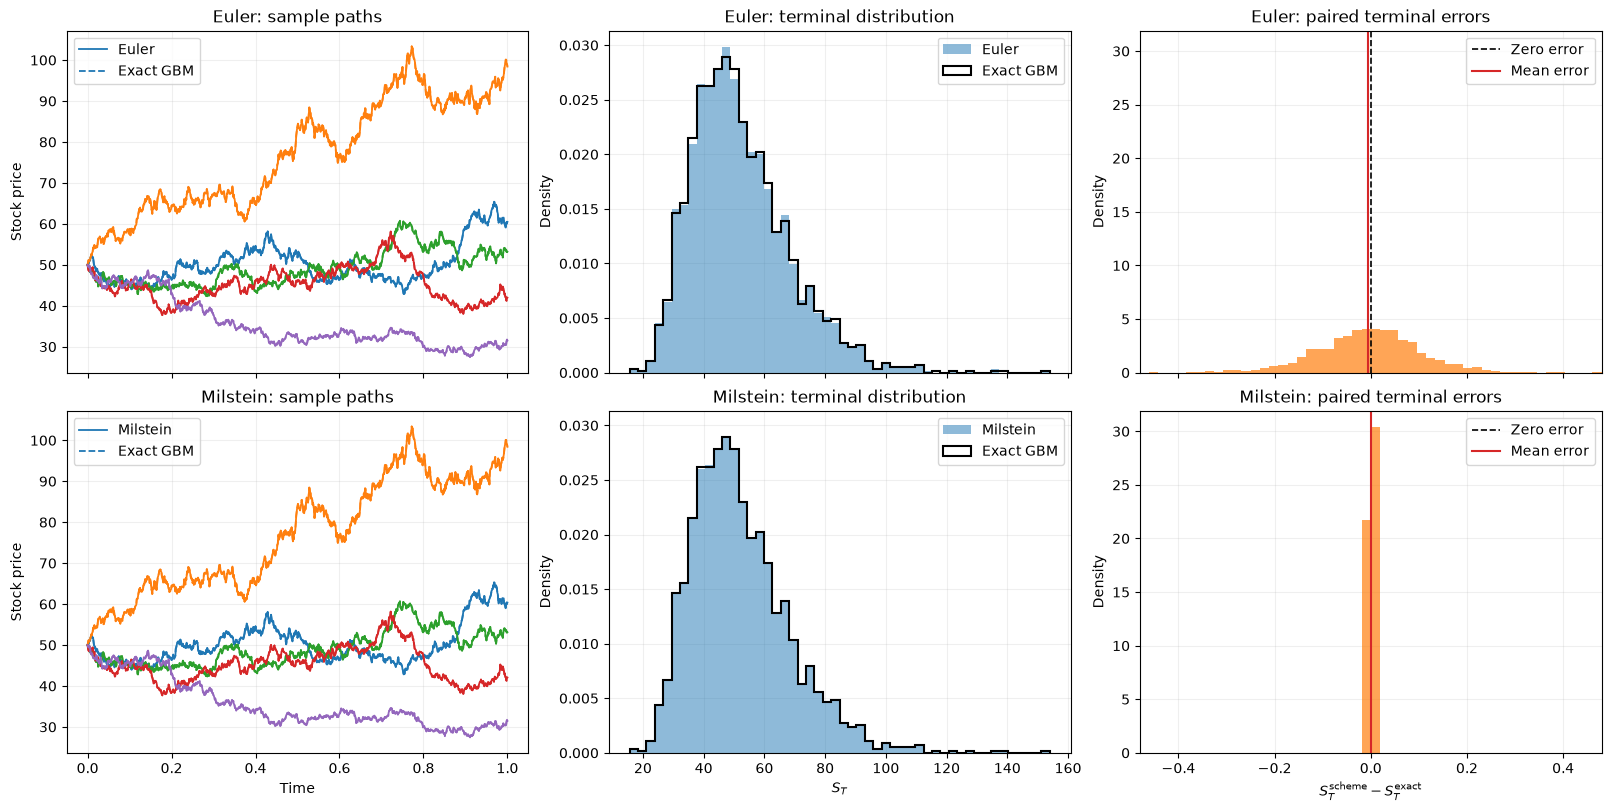

In [41]:
fig, axes = Plotting.plot_gbm_comparison(
    paths["euler"],
    paths["milstein"],
    paths_to_show=5,
    bins=50,
)

plt.show()

<!-- On the lhs we plot five sample paths for euler and milstein. In the middle we have the distributon of terminal paths values. On the rhs we plot the historgram of the errors, that is the difference between simulated and exact paths. Altough the lhs path plots look similar, we see that the error distribution is much narrower for milstein, which is not suprising since the higher order term makes the approximation better.  -->
On the left, we plot five sample paths for Euler and Milstein alongside their exact references. The middle panels show the terminal-price distributions. On the right, we plot the paired terminal errors $\widehat S_M^{(j)}-S^{(j)}(T)$ using shared bins and axis limits.

Although the paths and terminal-price distributions look similar, the error distribution is much narrower for Milstein. Its additional correction improves pathwise accuracy, consistent with strong convergence order one compared with Euler's order one-half.

<!-- By decreading the size or equivalently increasing the number of the time steps we can study the discretization error. We differentiate between strong and weak convergence. The approximation $\hat{S}_M$ converges in the strong sense to $S(T)$ with order $\alpha>0$ if    
$$ \epsilon^{strong}(\Delta t) = \mathbb{E}^Q\big[|\hat{S}_M-S(T)|\big] = \mathcal{O}(h^\alpha) $$
and in the weak sense with order $\beta$ if 
$$ \epsilon^{weak}(\Delta t) = \Big|\mathbb{E}^Q[\hat{S}_M] - \mathbb{E}^Q[S(T)]\Big| = \mathcal{O}(h^\beta).$$ -->

## Discretization Error

By decreasing the time-step size, or equivalently increasing the number of time steps at fixed maturity, we can study the discretization error. We distinguish between strong and weak convergence.

The approximation $\widehat S_M$ converges strongly to $S(T)$ with order $\alpha>0$ if
$$
\epsilon^{\mathrm{strong}}(\Delta t)
=\mathbb E^{\mathbb Q}\left[|\widehat S_M-S(T)|\right]
=\mathcal O((\Delta t)^\alpha).
$$
The approximate and exact solutions must use the same Brownian path.

Weak convergence concerns expectations of test functions. For a sufficiently smooth test function $g$, the weak error is
$$
\epsilon_g^{\mathrm{weak}}(\Delta t)
=\left|\mathbb E^{\mathbb Q}[g(\widehat S_M)]
-\mathbb E^{\mathbb Q}[g(S(T))]\right|.
$$
A scheme has weak order $\beta>0$ if this error is $\mathcal O((\Delta t)^\beta)$ for the relevant class of test functions.

Here, we use $g(s)=s$, comparing the expected terminal stock prices. 


We compare convergence with and without moment matching to investigate its effect on sampling noise.
Moment matching standardizes the normal draws across paths at each time step:

    Z[:, i] = (Z[:, i] - np.mean(Z[:, i])) / np.std(Z[:, i])

This forces their sample mean to zero and their sample variance to one.

We do not use moment matching throughout because it introduces dependence between simulated paths, so the usual standard-error formula $s/\sqrt{N}$ and the associated confidence intervals are no longer directly justified.

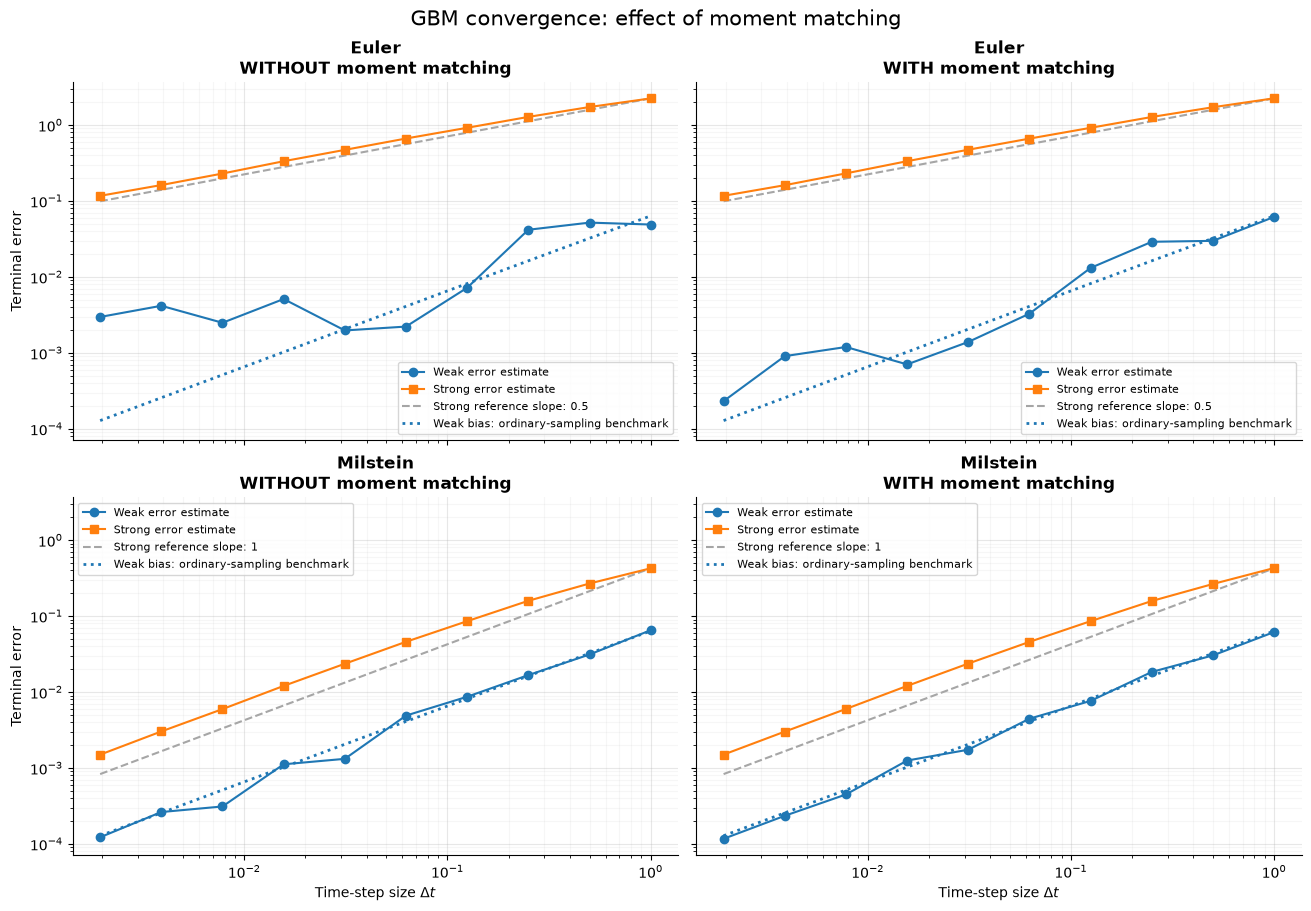

In [42]:
step_counts = 2 ** np.arange(10)

N = 5000
T = 1
r = 0.05
sigma = 0.3
S_0 = 50

seed = 42

discretization_results = {}

for scheme in ("euler", "milstein"):
    for matching in (False, True):

        np.random.seed(seed)

        discretization_results[(scheme, matching)] = (
            MonteCarloPricing.weak_and_strong_convergence(
                N,
                step_counts,
                T,
                r,
                sigma,
                S_0,
                scheme=scheme,
                moment_matching=matching,
            )
        )

fig, axes = Plotting.plot_convergence_matching_comparison(
    discretization_results,
    S_0,
    r,
    T,
)

plt.show()

For GBM, Euler has strong order $1/2$ and Milstein has strong order $1$, while both have weak order $1$ for sufficiently smooth test functions.
The strong-error curves are consistent with order $1/2$ for Euler and order $1$ for Milstein. Milstein produces substantially smaller pathwise errors, especially at small time steps.

For the weak test, both schemes have theoretical order one and the same bias under ordinary sampling. Milstein's weak-error estimates closely follow the analytical benchmark, whereas Euler's estimates are more affected by sampling noise. Moment matching improves agreement at several step sizes but does not eliminate these fluctuations. Its effect on the strong errors and on Milstein's weak estimates is small in this experiment. Quantifying variance reduction would require repeated independent runs.

## Pricing of European call and put options 

In [5]:
N = 10000
M = 5000

scheme = "milstein"

option_type = "call"
T = 1
r = 0.06
sigma = 0.3
S_0 = 5
K = S_0



S_T = (MonteCarloPricing.generate_GBM_paths(N, M, T, r, sigma, S_0, scheme))["S_approx"][:,-1]

print(S_T)
print(type(S_T))

mc_call_price = MonteCarloPricing.mc_call_put_price(option_type,S_T,K,T,r)

analytical_call_price = (MonteCarloPricing.analytical_BS_call_put_price(option_type,S_0,K,T,r,sigma))

print(f"Monte Carlo price:\t{mc_call_price["price"]:.3f} +- {mc_call_price["standard_error"]:.3f}")
print(f"Black-Scholes price:\t{analytical_call_price:.3f}")
print(f"Error between the two:\t{mc_call_price["price"]-analytical_call_price:.3f}")

[7.57379028 5.01251182 4.22547115 ... 4.51837644 6.48549924 4.73153631]
<class 'numpy.ndarray'>
Monte Carlo price:	0.736 +- 0.011
Black-Scholes price:	0.736
Error between the two:	0.000


## MC Sampling Error

We study sampling error by increasing the number of paths $N$ while keeping all other parameters fixed. We reuse the same random seed to make the comparison reproducible and use the Euler, Milstein, and exact-GBM simulations.

For each scheme, we compare the estimated option price with Black–Scholes and calculate the standard error and an approximate 95% confidence interval. Exact-GBM pricing contains only sampling error, whereas Euler and Milstein also introduce time-discretization bias.

In [44]:
path_counts =  [100,1000,5000,10000,50000,100000]
option_type = "call"
T = 1
r = 0.06
sigma = 0.3
S_0 = 5
K = S_0
M =1000
seed=1

pricing_results = MonteCarloPricing.mc_convergence(
        path_counts,
        M,
        option_type,
        S_0,
        K,
        T,
        r,
        sigma,
        seed,
)

Plotting.print_mc_convergence_table(pricing_results)

EUROPEAN OPTION PRICING
Black-Scholes price = 0.7359
Errors = MC price - Black-Scholes price

         N       Exact GBM           Euler        Milstein     Exact error     Euler error  Milstein error
----------------------------------------------------------------------------------------------------------
       100          0.9087          0.9092          0.9087          0.1728          0.1734          0.1728
     1,000          0.7390          0.7389          0.7389          0.0031          0.0031          0.0031
     5,000          0.7440          0.7440          0.7439          0.0081          0.0082          0.0081
    10,000          0.7361          0.7362          0.7361          0.0003          0.0003          0.0002
    50,000          0.7285          0.7285          0.7284         -0.0074         -0.0074         -0.0074
   100,000          0.7320          0.7320          0.7320         -0.0039         -0.0038         -0.0039


The three schemes produce very similar prices, indicating that sampling error dominates the differences between schemes for the chosen time grid. The realized pricing error does not decrease monotonically with $N$: a larger sample improves precision but does not guarantee a closer estimate in every run.

The standard errors decrease approximately as $N^{-1/2}$, and the confidence intervals narrow accordingly. These intervals describe sampling uncertainty; they do not account for Euler or Milstein discretization bias. Milstein's improved pathwise accuracy therefore does not necessarily produce a price closer to Black–Scholes in an individual simulation.

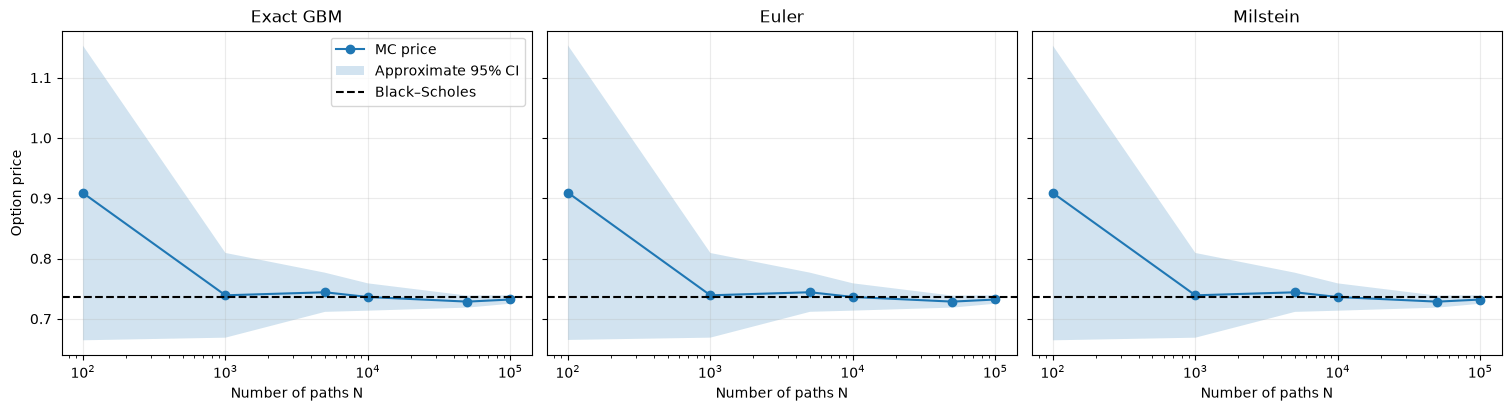

In [46]:
fig, axes = Plotting.plot_mc_convergence(pricing_results)
plt.show()

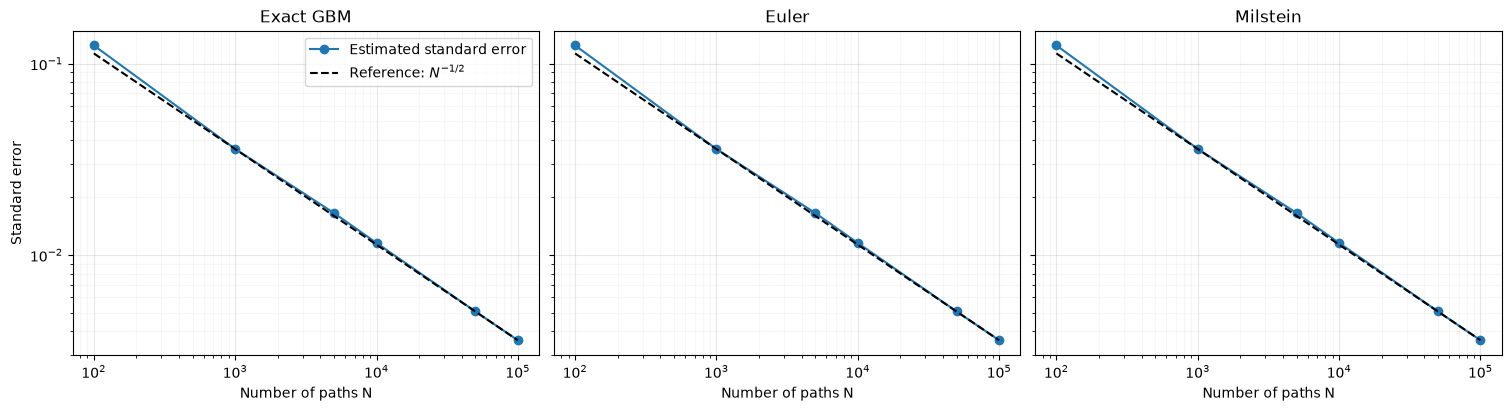

In [47]:
fig, axes = Plotting.plot_mc_standard_error(pricing_results)
plt.show()

In [ ]:
# path_counts = [100, 500, 1000, 5000, 10000]
# repetitions = 200

# option_type = "call"
# T = 1
# r = 0.06
# sigma = 0.3
# S_0 = 5
# K = S_0


# rng = np.random.default_rng(42)

# for N in path_counts:
#     S_T = []
#     for i in range(repetitions):
#         Z = rng.standard_normal(N)

#         S_T.append(S_0 * np.exp(
#             (r - 0.5 * sigma**2) * T
#             + sigma * np.sqrt(T) * Z
#         ))

#     S_T = np.asarray(S_T)

#     stats = MonteCarloPricing.mc_call_put_price(
#         option_type, S_T, K, T, r
#     )

#     bs_price = MonteCarloPricing.analytical_BS_call_put_price(option_type,S_0,K,T,r,sigma)

#     prices=stats["price"]
#     standard_errors=stats["standard_error"]
#     print(stats["ci_lower"] <= bs_price <= stats["ci_upper"])

#     errors = np.asarray(prices) - bs_price

#     mean_error = np.mean(errors)
#     rmse = np.sqrt(np.mean(errors**2))
#     empirical_std = np.std(prices, ddof=1)

#     predicted_std = np.sqrt(
#         np.mean(np.asarray(standard_errors)**2)
#     )

    # coverage = np.mean(covered)

True
True
True
True
True


In [11]:
path_counts = [100, 500, 1000, 5000, 10000]
repetitions = 200

option_type = "call"
T = 1
r = 0.06
sigma = 0.3
S_0 = 5
K = S_0

rng = np.random.default_rng(42)

bs_price = MonteCarloPricing.analytical_BS_call_put_price(
    option_type, S_0, K, T, r, sigma
)

validation_results = []

for N in path_counts:
    prices = []
    standard_errors = []
    covered = []

    for _ in range(repetitions):
        Z = rng.standard_normal(N)

        S_T = S_0 * np.exp(
            (r - 0.5 * sigma**2) * T
            + sigma * np.sqrt(T) * Z
        )

        stats = MonteCarloPricing.mc_call_put_price(
            option_type, S_T, K, T, r
        )

        prices.append(stats["price"])
        standard_errors.append(stats["standard_error"])
        covered.append(
            stats["ci_lower"] <= bs_price <= stats["ci_upper"]
        )

    prices = np.asarray(prices)
    standard_errors = np.asarray(standard_errors)
    errors = prices - bs_price

    validation_results.append({
        "N": N,
        "mean_error": np.mean(errors),
        "rmse": np.sqrt(np.mean(errors**2)),
        "empirical_std": np.std(prices, ddof=1),
        "predicted_std": np.sqrt(np.mean(standard_errors**2)),
        "coverage": np.mean(covered),
    })

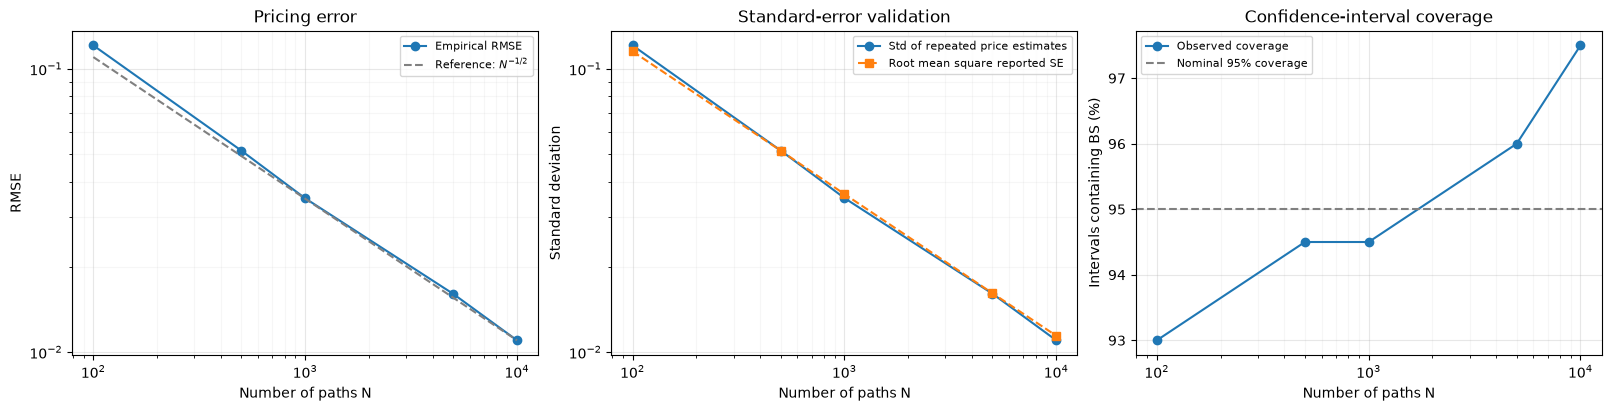

In [12]:
N_values = np.array([row["N"] for row in validation_results])
rmse = np.array([row["rmse"] for row in validation_results])
empirical_std = np.array([
    row["empirical_std"] for row in validation_results
])
predicted_std = np.array([
    row["predicted_std"] for row in validation_results
])
coverage = np.array([row["coverage"] for row in validation_results])

reference = rmse[-1] * (N_values / N_values[-1]) ** (-0.5)

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4),
    constrained_layout=True,
)

# 1. Observed pricing error.
axes[0].loglog(N_values, rmse, "o-", label="Empirical RMSE")
axes[0].loglog(
    N_values, reference, "--",
    color="gray",
    label=r"Reference: $N^{-1/2}$",
)
axes[0].set_title("Pricing error")
axes[0].set_ylabel("RMSE")

# 2. Observed versus predicted variability.
axes[1].loglog(
    N_values, empirical_std, "o-",
    label="Std of repeated price estimates",
)
axes[1].loglog(
    N_values, predicted_std, "s--",
    label="Root mean square reported SE",
)
axes[1].set_title("Standard-error validation")
axes[1].set_ylabel("Standard deviation")

# 3. Confidence-interval coverage.
axes[2].semilogx(
    N_values, 100 * coverage, "o-",
    label="Observed coverage",
)
axes[2].axhline(
    95, linestyle="--", color="gray",
    label="Nominal 95% coverage",
)
axes[2].set_title("Confidence-interval coverage")
axes[2].set_ylabel("Intervals containing BS (%)")

for ax in axes:
    ax.set_xlabel("Number of paths N")
    ax.grid(which="major", alpha=0.3)
    ax.grid(which="minor", alpha=0.1)
    ax.legend(fontsize=8)

plt.show()

## Put-Call-Parity

In [ ]:
# # def check_put_call_parity(
# #         S_T,
# #         K,
# #         T,
# #         r
# # ):

N=100000
T = 1
r = 0.06
sigma = 0.3
S_0 = 5
K = S_0
M =1000
seed=1
seed = 42

# terminal_prices = {}


# price_paths = MonteCarloPricing.generate_GBM_paths(
#     N, M, T, r, sigma, S_0, "milstein"
# )

# S_T = price_paths["S_approx"][:,-1]


# call_price = (MonteCarloPricing.mc_call_put_price("call",S_T,K,T,r))["price"]
# put_price = (MonteCarloPricing.mc_call_put_price("put",S_T,K,T,r))["price"]

# rhs = np.exp(-r*T) * (S_T - K) 

# print(call_price - put_price - rhs)

np.random.seed(seed)

price_paths = MonteCarloPricing.generate_GBM_paths(
    N, M, T, r, sigma, S_0,
    scheme="milstein",
    moment_matching=False,
)

S_T = price_paths["S_approx"][:, -1]

call_price = MonteCarloPricing.mc_call_put_price(
    "call", S_T, K, T, r
)["price"]

put_price = MonteCarloPricing.mc_call_put_price(
    "put", S_T, K, T, r
)["price"]

# Sample payoff identity: should hold up to rounding.
sample_rhs = np.exp(-r * T) * (np.mean(S_T) - K)

# Theoretical put–call parity.
theoretical_rhs = S_0 - K * np.exp(-r * T)

print(
    f"Sample identity residual: "
    f"{call_price - put_price - sample_rhs:.6e}"
)
print(
    f"Theoretical parity residual: "
    f"{call_price - put_price - theoretical_rhs:.6e}"
)